
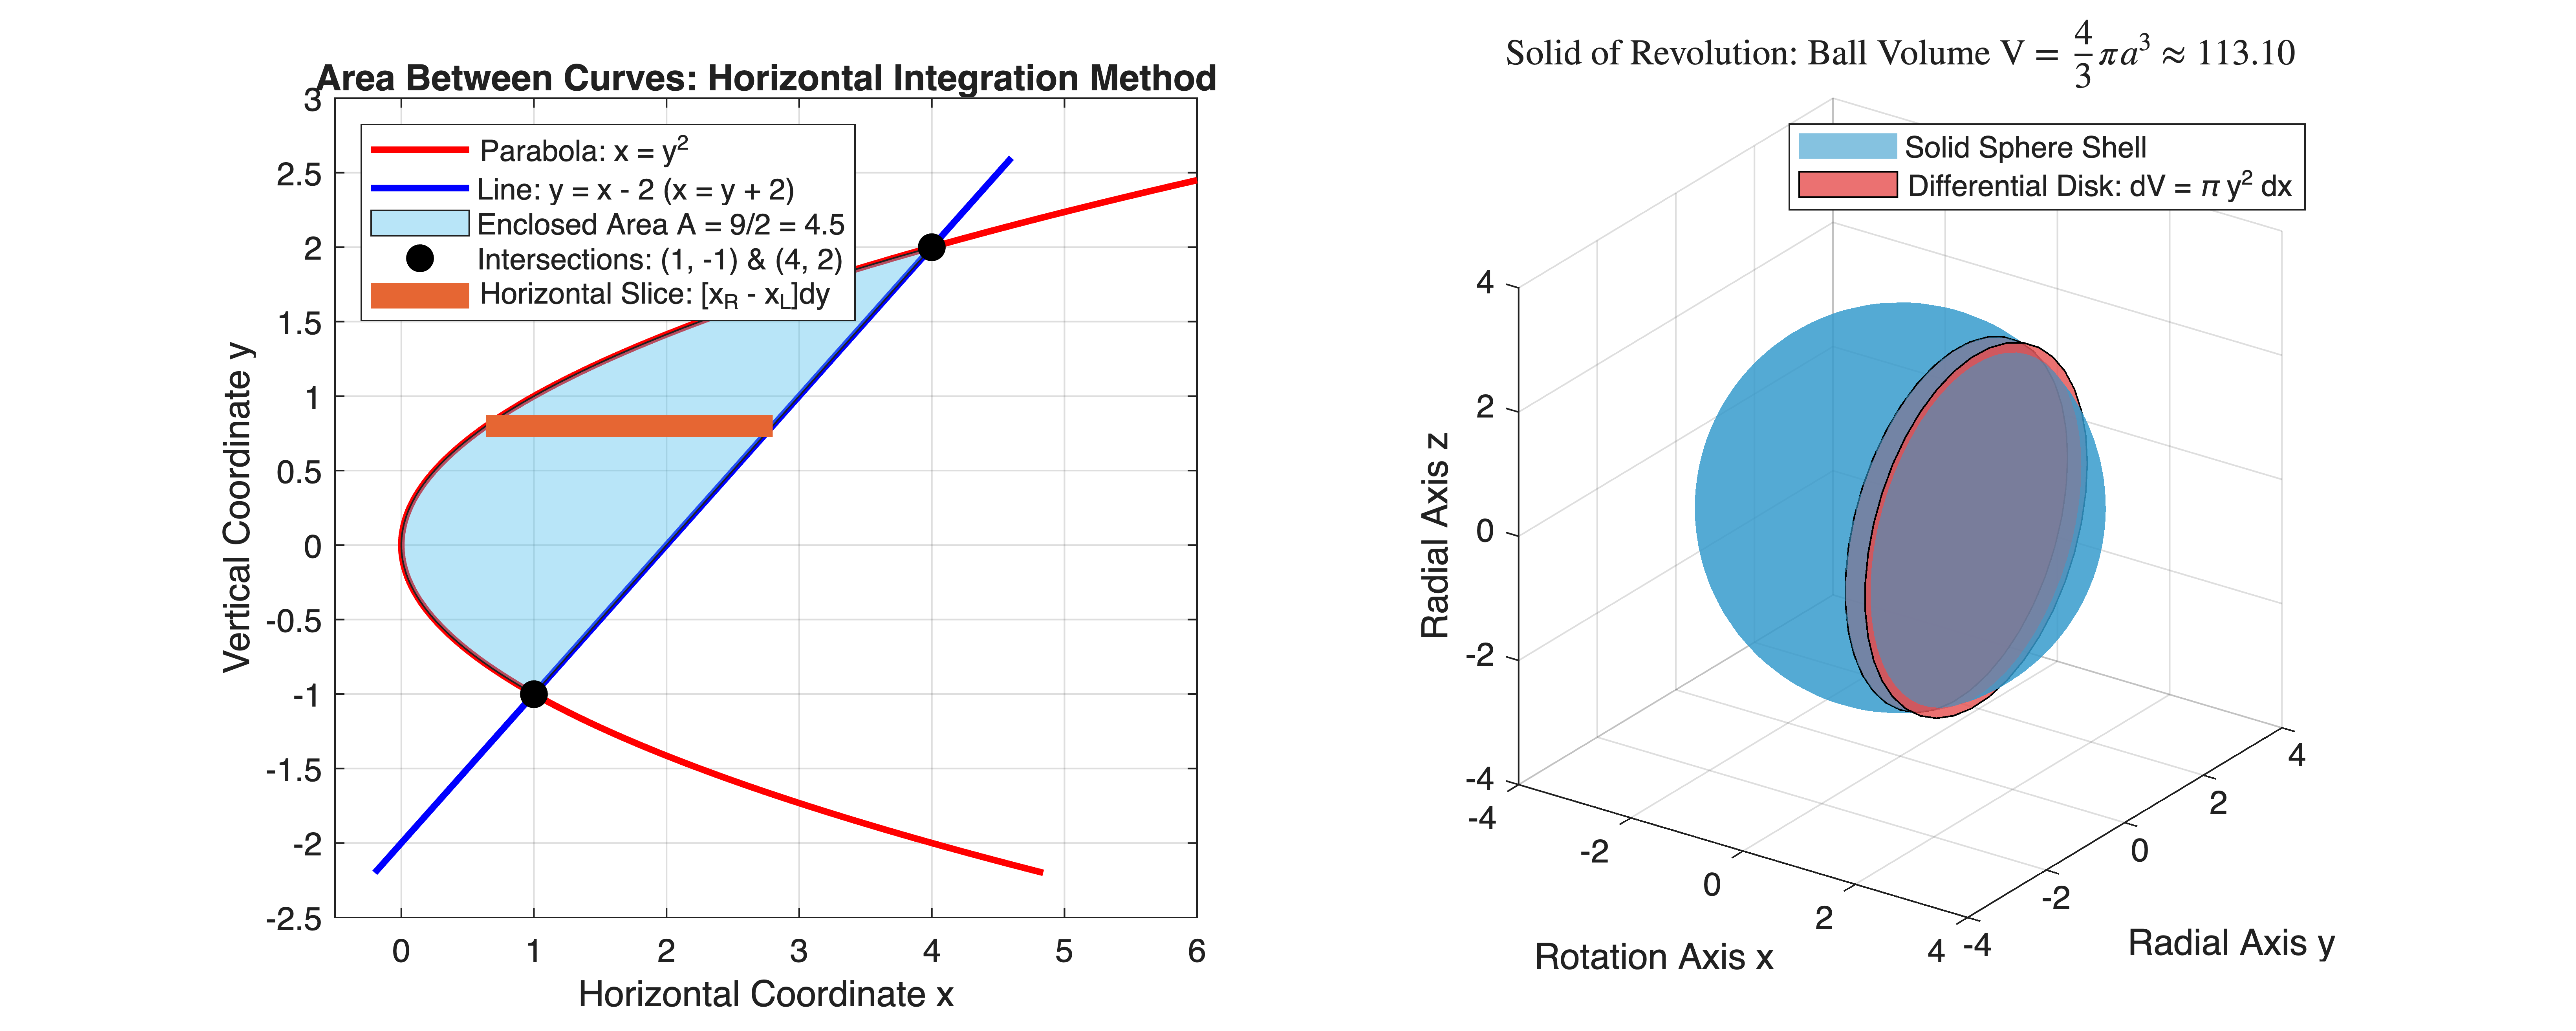

In [1]:
%% MIT 18.01 Lecture 21: Logarithm Integral & Geometric Slicing Simulation
% Mathematical Tool Application: Used for rigid body mass/inertia property extraction
% (volume of revolution via disk method) and manipulator workspace area evaluation.


clear; clc; close all;


%% Part 1: Enclosed Area Between Curves (x = y^2 and y = x - 2)
% Intersection points: y^2 - y - 2 = 0 => (y-2)(y+1)=0 => y = -1, 2
% Corresponds to (1, -1) and (4, 2)
y_int = [-1.0, 2.0];
x_int = [1.0, 4.0];


% Continuous evaluation spans
y_fill = linspace(y_int(1), y_int(2), 200);
x_parabola_fill = y_fill.^2;
x_line_fill = y_fill + 2.0;


figure('Color', 'w', 'Position', [100, 100, 1250, 500]);


subplot(1, 2, 1);
% Plot Curves
y_span = linspace(-2.2, 2.6, 400);
plot(y_span.^2, y_span, 'r-', 'LineWidth', 2.0, 'DisplayName', 'Parabola: x = y^2'); hold on;
plot(y_span + 2.0, y_span, 'b-', 'LineWidth', 2.0, 'DisplayName', 'Line: y = x - 2 (x = y + 2)');


% Fill enclosed area (Horizontal Slicing domain)
fill([x_parabola_fill, fliplr(x_line_fill)], [y_fill, fliplr(y_fill)], ...
    [0.3, 0.75, 0.93], 'FaceAlpha', 0.4, 'DisplayName', 'Enclosed Area A = 9/2 = 4.5');


% Plot intersection points
plot(x_int, y_int, 'ko', 'MarkerSize', 8, 'MarkerFaceColor', 'k', ...
    'DisplayName', 'Intersections: (1, -1) & (4, 2)');


% Draw a representative horizontal differential slice dy at y = 0.8
y_slice = 0.8;
dy = 0.15;
x_left_slice = y_slice^2;
x_right_slice = y_slice + 2.0;
patch([x_left_slice, x_right_slice, x_right_slice, x_left_slice], ...
    [y_slice - dy/2, y_slice - dy/2, y_slice + dy/2, y_slice + dy/2], ...
    [0.9, 0.4, 0.2], 'EdgeColor', 'none', 'DisplayName', 'Horizontal Slice: [x_R - x_L]dy');


grid on;
xlim([-0.5, 6.0]); ylim([-2.5, 3.0]);
xlabel('Horizontal Coordinate x');
ylabel('Vertical Coordinate y');
title('Area Between Curves: Horizontal Integration Method');
legend('Location', 'northwest');


%% Part 2: 3D Solid of Revolution via Disk Method (Sphere Radius a = 3)
subplot(1, 2, 2);
radius_a = 3.0;


% Generate surface of revolution around x-axis: x in [-a, a]
[X_mesh, theta_mesh] = meshgrid(linspace(-radius_a, radius_a, 60), linspace(0, 2*pi, 60));
R_at_x = sqrt(max(0, radius_a^2 - X_mesh.^2)); % y(x) = sqrt(a^2 - x^2)
Y_mesh = R_at_x .* cos(theta_mesh);
Z_mesh = R_at_x .* sin(theta_mesh);


% Render 3D Revolving Shell
surf(X_mesh, Y_mesh, Z_mesh, 'FaceColor', [0.2, 0.6, 0.8], 'FaceAlpha', 0.6, ...
    'EdgeColor', 'none', 'DisplayName', 'Solid Sphere Shell'); hold on;


% Render a sample differential disk slice at x = 1.0
x_disk = 1.0;
dx_disk = 0.35;
r_disk = sqrt(radius_a^2 - x_disk^2);
theta_disk = linspace(0, 2*pi, 40);


% Disk front and back caps
fill3(x_disk * ones(size(theta_disk)), r_disk*cos(theta_disk), r_disk*sin(theta_disk), ...
    [0.9, 0.3, 0.3], 'FaceAlpha', 0.8, 'EdgeColor', 'k', 'DisplayName', 'Differential Disk: dV = \pi y^2 dx');
fill3((x_disk+dx_disk) * ones(size(theta_disk)), r_disk*cos(theta_disk), r_disk*sin(theta_disk), ...
    [0.9, 0.3, 0.3], 'FaceAlpha', 0.8, 'EdgeColor', 'k', 'HandleVisibility', 'off');


axis equal; grid on;
view(35, 25);
xlim([-4, 4]); ylim([-4, 4]); zlim([-4, 4]);
xlabel('Rotation Axis x');
ylabel('Radial Axis y');
zlabel('Radial Axis z');
title(sprintf('Solid of Revolution: Ball Volume V = $\\frac{4}{3}\\pi a^3 \\approx %.2f$', (4/3)*pi*radius_a^3), 'Interpreter', 'latex');
legend('Location', 'northeast');